<a href="https://colab.research.google.com/github/GalynaGnatenko/GnatenkoGalyna/blob/main/%D0%93%D0%BD%D0%B0%D1%82%D0%B5%D0%BD%D0%BA%D0%BE_%22HW_11_3_%D0%A1%D1%82%D0%B0%D1%82%D0%B8%D1%81%D1%82%D0%B8%D1%87%D0%BD%D1%96_%D0%B2%D1%96%D0%B7%D1%83%D0%B0%D0%BB%D1%96%D0%B7%D0%B0%D1%86%D1%96%D1%97_%D0%B7_Seaborn_ipynb%22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Домашнє завдання: Статистичні візуалізації з Seaborn

## Опис завдання
У цьому домашньому завданні ви будете використовувати бібліотеку Seaborn для створення красивих статистичних візуалізацій. Seaborn має кращий стандартний стиль та спеціалізується на статистичних графіках.

**Опис колонок:**
- `datetime` - дата та час
- `season` - квартал (1-Q1, 2-Q2, 3-Q3, 4-Q4)
- `holiday` - чи є день святковим (0=ні, 1=так)
- `workingday` - чи є день робочим (0=ні, 1=так)
- `weather` - погодні умови (1=ясно, 2=туман, 3=легкий дощ, 4=сильний дощ)
- `temp` - температура в градусах Цельсія
- `atemp` - як відчувається температура
- `humidity` - вологість (%)
- `windspeed` - швидкість вітру
- `casual` - кількість випадкових користувачів
- `registered` - кількість зареєстрованих користувачів
- `count` - загальна кількість орендованих велосипедів

## Підготовка даних

---
🌱 Коментар щодо сезонності

Колонка season у датасеті представляє саме квартали року, а не метеорологічні сезони. Тому всі аналізи сезонності ви можете будувати на основі кварталів.

Водночас дані були зібрані в Індії, де поділ на сезони інший, ніж у Європі чи США. Якщо ви хочете дослідити сезонність відповідно до індійської системи сезонів, можна створити окрему колонку.

Справжні сезони в Індії:

| Сезон        | Місяці                     |
| ------------ | -------------------------- |
| Winter       | December–February (12,1,2) |
| Summer       | March–May (3,4,5)          |
| Monsoon      | June–September (6,7,8,9)   |
| Post-monsoon | October–November (10,11)   |


Тоді потрібно зробити нову колонку weather_season_india, мапнувши місяці так:

12, 1, 2 → 1 (Winter)

3, 4, 5 → 2 (Summer)

6–9 → 3 (Monsoon)

10–11 → 4 (Post-Monsoon)

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Завантаження даних
from google.colab import drive
drive.mount('/content/drive')
# Завантаження даних
df = pd.read_csv('/content/drive/MyDrive/Data/yulu_rental.csv')

# Встановлюємо стиль seaborn
sns.set_theme(style="whitegrid")

df['datetime'] = pd.to_datetime(df['datetime'])

# Додамо додаткові колонки для аналізу

df['date'] = df['datetime'].dt.date
df['day'] = df['datetime'].dt.day
df['week'] = df['datetime'].dt.isocalendar().week
df['weekday_num'] = df['datetime'].dt.weekday
df['weekday'] = df['datetime'].dt.day_name()
df['year'] = df['datetime'].dt.year
df['month'] = df['datetime'].dt.month
df['hour'] = df['datetime'].dt.hour

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [4]:
df

,datetime,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count,date,day,week,weekday_num,weekday,year,month,hour
0,2011-01-01 00:00:00,1,0,0,1,9.84,14.395,81,0.0000,3,13,16,2011-01-01,1,52,5,Saturday,2011,1,0
1,2011-01-01 01:00:00,1,0,0,1,9.02,13.635,80,0.0000,8,32,40,2011-01-01,1,52,5,Saturday,2011,1,1
2,2011-01-01 02:00:00,1,0,0,1,9.02,13.635,80,0.0000,5,27,32,2011-01-01,1,52,5,Saturday,2011,1,2
3,2011-01-01 03:00:00,1,0,0,1,9.84,14.395,75,0.0000,3,10,13,2011-01-01,1,52,5,Saturday,2011,1,3
4,2011-01-01 04:00:00,1,0,0,1,9.84,14.395,75,0.0000,0,1,1,2011-01-01,1,52,5,Saturday,2011,1,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10881,2012-12-19 19:00:00,4,0,1,1,15.58,19.695,50,26.0027,7,329,336,2012-12-19,19,51,2,Wednesday,2012,12,19
10882,2012-12-19 20:00:00,4,0,1,1,14.76,17.425,57,15.0013,10,231,241,2012-12-19,19,51,2,Wednesday,2012,12,20
10883,2012-12-19 21:00:00,4,0,1,1,13.94,15.910,61,15.0013,4,164,168,2012-12-19,19,51,2,Wednesday,2012,12,21
10884,2012-12-19 22:00:00,4,0,1,1,13.94,17.425,61,6.0032,12,117,129,2012-12-19,19,51,2,Wednesday,2012,12,22



---

## Завдання 1: Лінійний графік з довірчими інтервалами

**Завдання:**
Побудуйте лінійний графік середньої кількості оренд помісячно з довірчими інтервалами (confidence intervals) рівними 1 стандартному відхиленню.

**УВАГА!** В лекції ми будували подібний графік, але там були дані по номеру місяця, а тут треба зобразити дані в розрізі місяць_рік.

В якості підказки вам наведений код для створення колонки, яка містить `місяць_рік`. Як її використати - вже питання до вас :)

Очікуваний результат:
![](https://drive.google.com/uc?id=1uVKqfY1VlhVMaM3wu99uVGT1f7S0Vf8S)

**Питання для інтерпретації:**
- В які місяці найбільша невизначеність в даних?

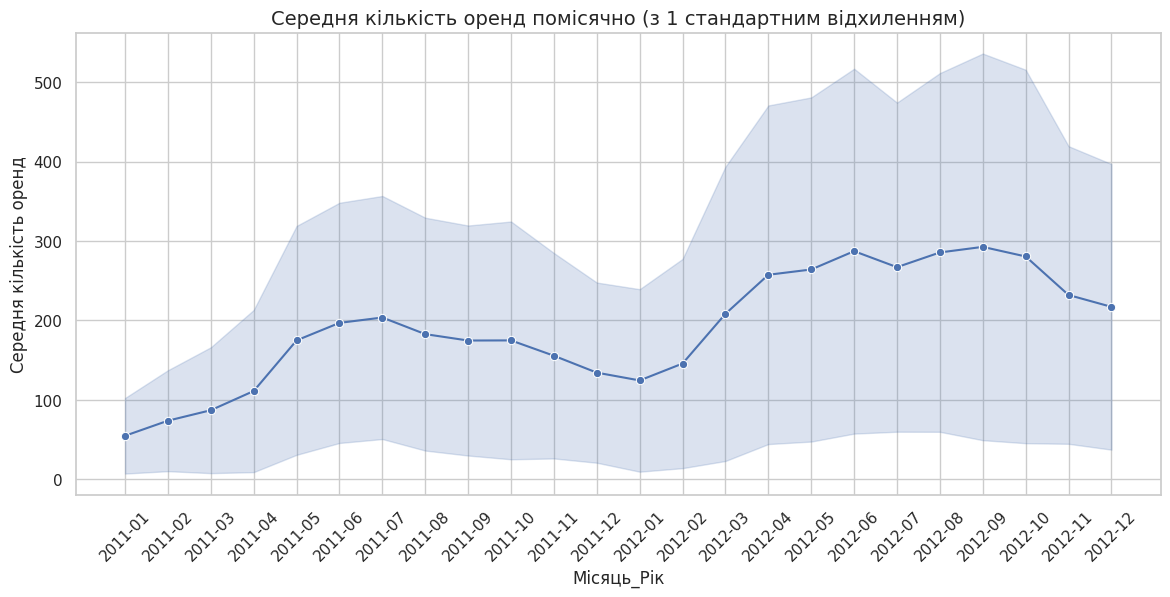

In [6]:
df['datetime'] = pd.to_datetime(df['datetime'])

# 2. Створюємо колонку 'month_year' точно за наданою підказкою
df['month_year'] = df['datetime'].dt.to_period('M').astype(str)

# 3. Побудова лінійного графіка через Seaborn
plt.figure(figsize=(14, 6))

sns.lineplot(
    data=df,
    x='month_year',
    y='count',
    marker='o',
    errorbar=('sd', 1) # або ci='sd', якщо у вас старіша версія seaborn
)

plt.title('Середня кількість оренд помісячно (з 1 стандартним відхиленням)', fontsize=14)
plt.xlabel('Місяць_Рік', fontsize=12)
plt.ylabel('Середня кількість оренд', fontsize=12)
plt.xticks(rotation=45)

plt.show()

В які місяці найбільша невизначеність в даних? - в 2012 році. особливо в червні, вересні. бо сіра область найбільше віддаляється від центральної синьої лінії. в теплий період зростає попит. та виникають значні викиди. пікова кількість оренди.

## Завдання 2: Порівняння стилів - Pandas vs Seaborn гістограма

**Завдання:**
Побудуйте гістограму розподілу температури двома способами - з Pandas та Seaborn - та порівняйте візуальний вигляд. Задайте однакову кількість бінів в цих візуалізаціях, відмінну від стандартної. В візуалізації Seaborn додайте параметр при побудові `kde=True`.

**Функція Seaborn: `sns.histplot()`**

Можна побудувати окремо два графіки. Але для тих, хто хоче складніше - побудуйте ці 2 графіки на 1 фігурі.

**Дайте відповідь на питання:**
1. Яка візуальна різниця між Pandas та Seaborn гістограмами?
2. Що за лінія додаткова на графіку в Seaborn? Як вона називається і як ви б її описали своїми словами?

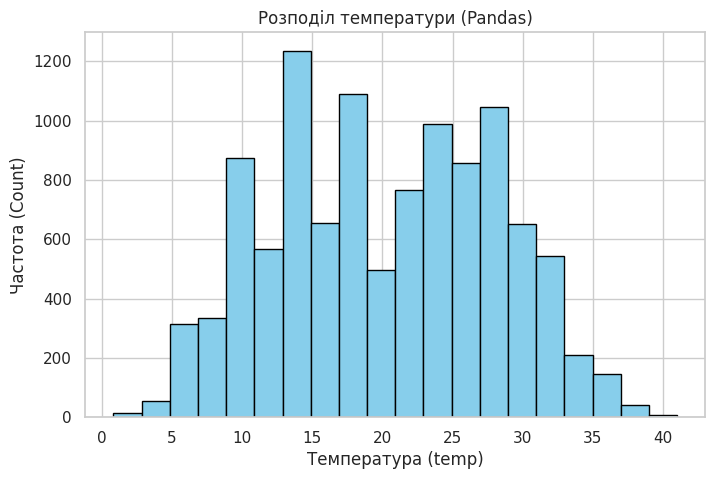

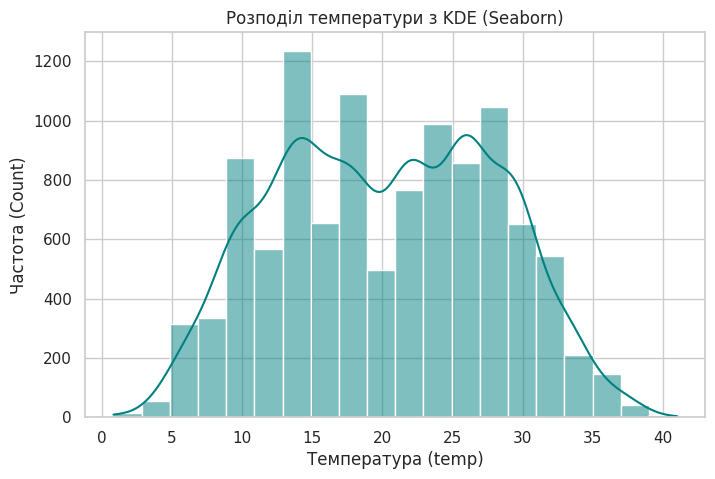

In [7]:
plt.figure(figsize=(8, 5))
df['temp'].plot(
    kind='hist',
    bins=20,
    color='skyblue',
    edgecolor='black',
    title='Розподіл температури (Pandas)'
)
plt.xlabel('Температура (temp)')
plt.ylabel('Частота (Count)')
plt.show()

# --- 2. Гістограма через Seaborn ---
plt.figure(figsize=(8, 5))
sns.histplot(
    data=df,
    x='temp',
    bins=20,
    kde=True,
    color='teal'
)
plt.title('Розподіл температури з KDE (Seaborn)')
plt.xlabel('Температура (temp)')
plt.ylabel('Частота (Count)')
plt.show()

Дайте відповідь на питання:

Яка візуальна різниця між Pandas та Seaborn гістограмами? - мені більше подобається другий. він більш сучасний
Що за лінія додаткова на графіку в Seaborn? Як вона називається і як ви б її описали своїми словами? - KDE (Kernel Density Estimate) — оцінка ядерної щільності.. показує загальну форму розподілу даних. Вона допомагає одразу побачити, де знаходяться головні піки (найчастіші значення)

## Завдання 3: Box Plot порівняння - Pandas vs Seaborn

**Завдання:**
Побудуйте box plot для кількості погодинних оренд велосипедів за погодними умовами з Pandas та Seaborn.

**Функція Seaborn: `sns.boxplot()`**

Можна побудувати окремо два графіки. Але для тих, хто хоче складніше - побудуйте ці 2 графіки на 1 фігурі.

Просунуте доповнення:
- підпишіть погодні умови їх інтерпретацією з опису даних в обох графіках

**Дайте відповідь на питання:**
- Яка візуальна різниця між Pandas та Seaborn бокс-плотами?

/tmp/ipykernel_5769/2660199568.py:30: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


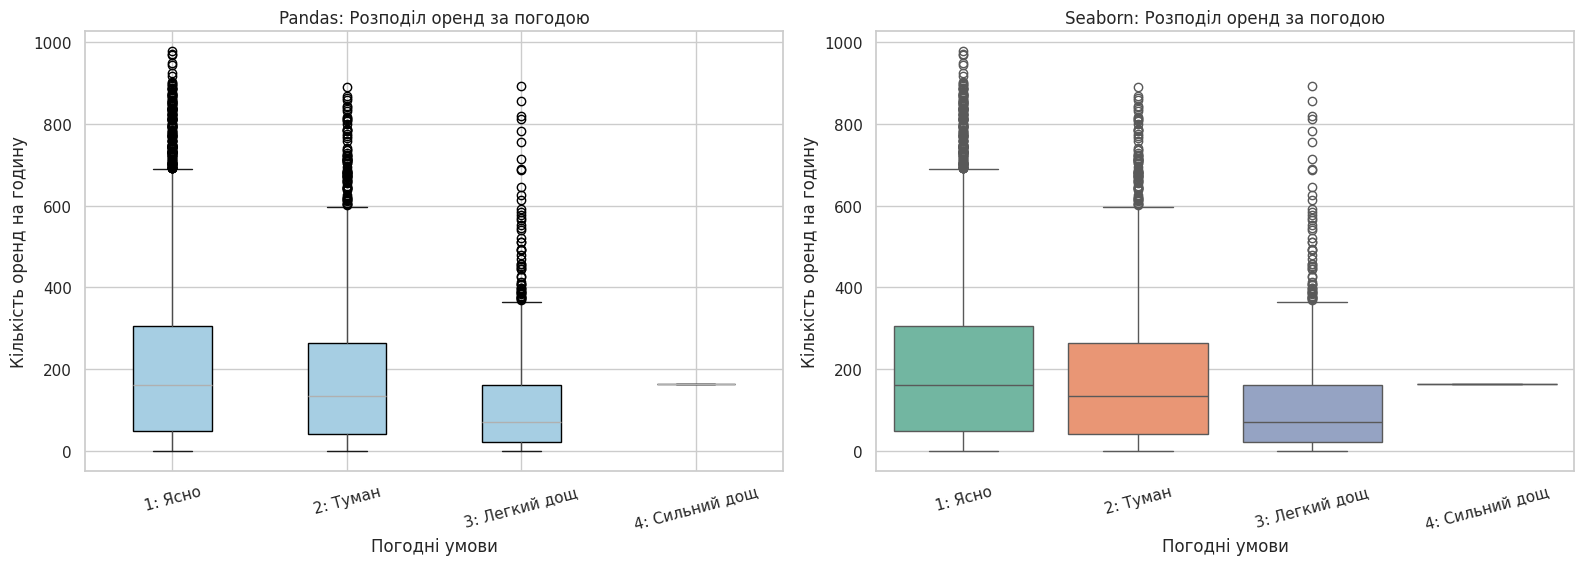

In [9]:
weather_labels = {
    1: '1: Ясно',
    2: '2: Туман',
    3: '3: Легкий дощ',
    4: '4: Сильний дощ'
}

# 2. Додаємо нову колонку з підписами
df['weather_desc'] = df['weather'].map(weather_labels)

# 3. Створюємо фігуру з 2 графіками (1 рядок, 2 колонки)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# --- Графік 1: Pandas ---
df.boxplot(
    column='count',
    by='weather_desc',
    ax=axes[0],
    grid=True,
    patch_artist=True,
    boxprops=dict(facecolor='#a6cee3')
)
axes[0].set_title('Pandas: Розподіл оренд за погодою', fontsize=12)
axes[0].set_xlabel('Погодні умови')
axes[0].set_ylabel('Кількість оренд на годину')
axes[0].tick_params(axis='x', rotation=15)
fig.suptitle('') # Видаляємо автоматичний верхній заголовок Pandas

# --- Графік 2: Seaborn ---
sns.boxplot(
    data=df,
    x='weather_desc',
    y='count',
    ax=axes[1],
    palette='Set2'
)
axes[1].set_title('Seaborn: Розподіл оренд за погодою', fontsize=12)
axes[1].set_xlabel('Погодні умови')
axes[1].set_ylabel('Кількість оренд на годину')
axes[1].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()

Дайте відповідь на питання:

Яка візуальна різниця між Pandas та Seaborn бокс-плотами? - на мій погляд візуалізація майже однакова. в другому графіку додані кольори. Але саме візуально мені більш довподоби перший графік. я краще відчула різницю між значеннями. Що при погоді "ясно" середня кількість найбільша. В другому графіку box самі по собі більше. Та візуально мені було складно побачити, який найбільший з них

<!-- - -->
## Завдання 4: Heatmap кореляційної матриці

**Завдання:**
Створіть із Seaborn кореляційну матрицю з забарвленням heatmap (колір відповідає величині значення в клітинці) числових змінних в наших даних з анотаціями значень.

**Дайте відповіді на питання по графіку:**
1. Які змінні найсильніше корелюють з загальною кількістю оренди (count)?
2. Яка кореляція між temp та atemp? Чому?
3. Які змінні мають негативну кореляцію?


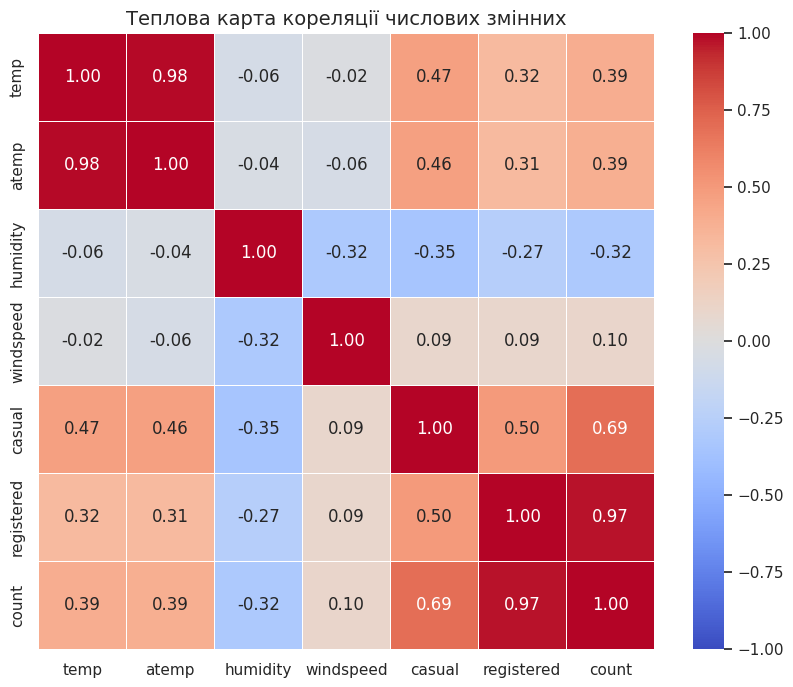

In [10]:
numeric_cols = ['temp', 'atemp', 'humidity', 'windspeed', 'casual', 'registered', 'count']
corr_matrix = df[numeric_cols].corr()

# 2. Побудова теплової карти (Heatmap)
plt.figure(figsize=(10, 8))

sns.heatmap(
    corr_matrix,
    annot=True,          # Відображення значень у клітинках
    fmt='.2f',           # Округлення до 2 знаків після коми
    cmap='coolwarm',     # Колірна палітра (синій — негативна, червоний — позитивна)
    vmin=-1, vmax=1,     # Шкала від -1 до 1
    linewidths=0.5,      # Розділювальні лінії між клітинками
    square=True          # Квадратна форма клітинок
)

plt.title('Теплова карта кореляції числових змінних', fontsize=14)
plt.show()

1. Які змінні найсильніше корелюють з загальною кількістю оренди (count)? - registered  - кількість зареєстрованих. вони беруть найчастіше. все логічно
2. Яка кореляція між temp та atemp? Чому?-  показник = 0,98. Реальна температура та температура, яку людина відчуває майже однакова
3. Які змінні мають негативну кореляцію? - найбільша негативна кореляція по вологості. трохи менша, але все ж таки є - по силі вітру. Коли вітер катаються менше. коли дощ/туман/сніг - катаються ще менше

## Завдання 5: Violin Plot для глибокого аналізу розподілів

**Завдання:**
Створіть violin plot для аналізу розподілу оренди за кварталами.

Дайте відповіді на питання:

**Питання для інтерпретації:**
1. Що показує "товщина" violin plot?
2. В якому кварталі найбільша варіабельність оренди?
3. Яка перевага violin plot над звичайним box plot?


/tmp/ipykernel_5769/2096168480.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(


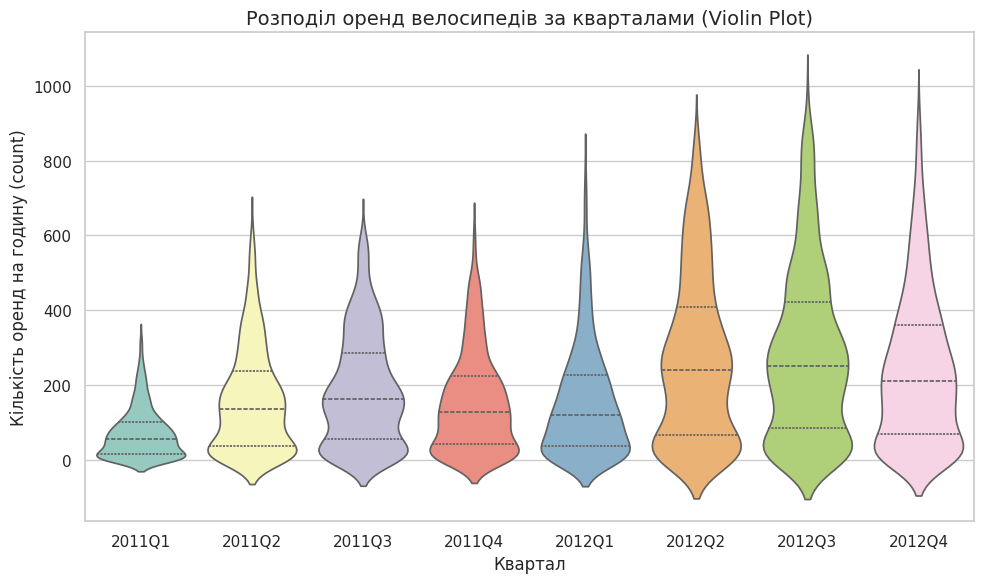

In [11]:
df['quarter'] = df['datetime'].dt.to_period('Q').astype(str)
# Або просто номер кварталу: df['quarter'] = df['datetime'].dt.quarter

plt.figure(figsize=(10, 6))

# 2. Побудова Violin Plot
sns.violinplot(
    data=df,
    x='quarter',
    y='count',
    palette='Set3',
    inner='quartile'  # Відображає квартилі всередині "скрипки"
)

plt.title('Розподіл оренд велосипедів за кварталами (Violin Plot)', fontsize=14)
plt.xlabel('Квартал', fontsize=12)
plt.ylabel('Кількість оренд на годину (count)', fontsize=12)

plt.tight_layout()
plt.show()

Питання для інтерпретації:

1. Що показує "товщина" violin plot? - частота виникнення даних
2. В якому кварталі найбільша варіабельність оренди? - в 3му кварталі 2012 року. У цей період фігура найдовша по вертикальній осі — від значень, близьких до нуля, до максимальних піків у 500+ оренд.
3. Яка перевага violin plot над звичайним box plot? - я побачила що є інформація по декільком пікам. Одразу видно, яке значення ці пікі мають в різні періоди.

## Завдання 6 : Pairplot для мультиваріативного аналізу

**Завдання:**
Створіть pairplot для аналізу взаємозв'язків між ключовими змінними `'temp', 'humidity', 'windspeed', 'count'` . В якості візуальної розбивки за категоріями (параметр `hue`) додайте season (квартал).

Дайте відповіді на питання:

**Питання для інтерпретації:**
1. Між якими змінними спостерігається найсильніший лінійний зв'язок?
2. Яка характеристика найбільше відрізняється між кварталами?

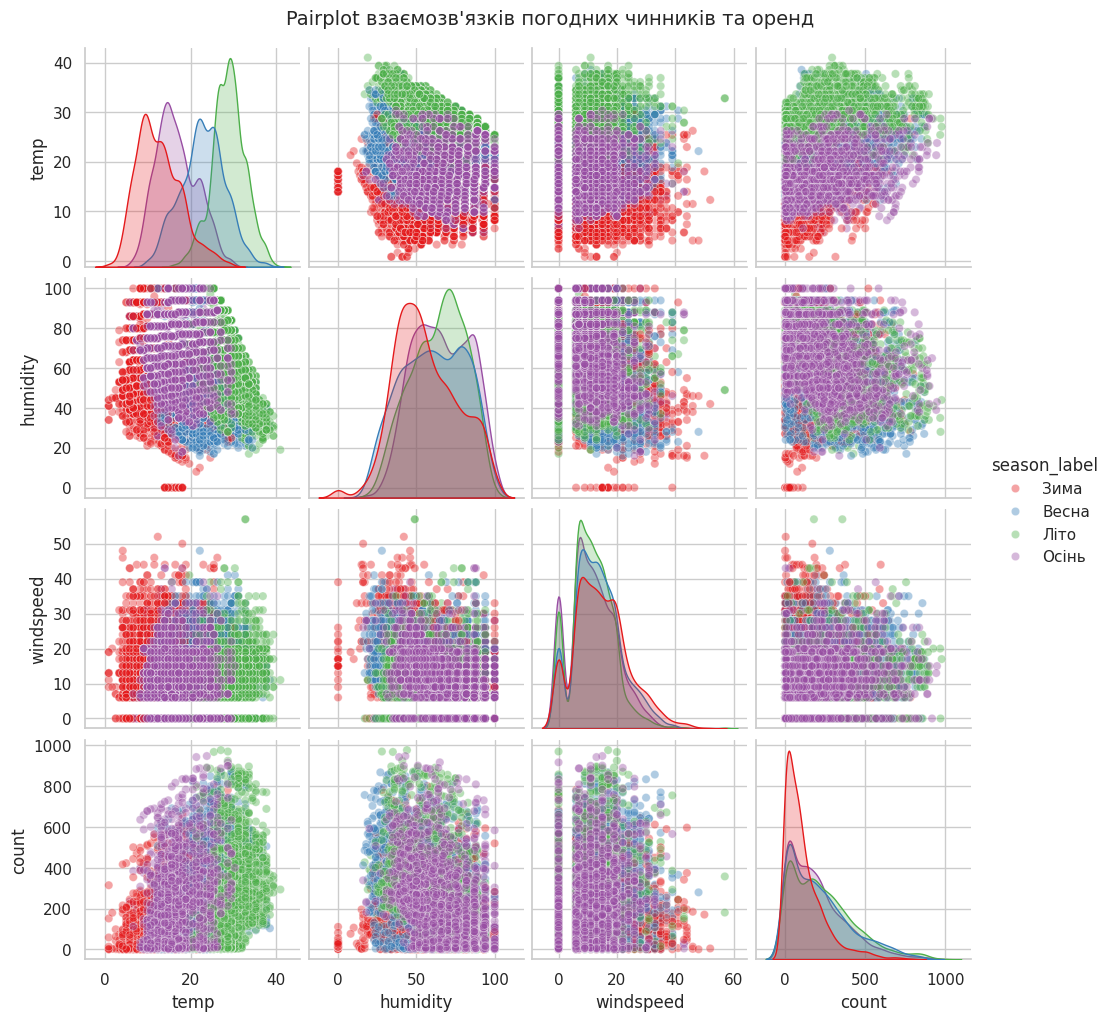

In [12]:
season_names = {1: 'Зима', 2: 'Весна', 3: 'Літо', 4: 'Осінь'}
df['season_label'] = df['season'].map(season_names)

# 2. Побудова Pairplot
sns.pairplot(
    data=df,
    vars=['temp', 'humidity', 'windspeed', 'count'],
    hue='season_label',
    palette='Set1',
    plot_kws={'alpha': 0.4},  # Прозорість точок для кращої читабельності
    diag_kind='kde'          # Графіки щільності на діагоналі
)

plt.suptitle('Pairplot взаємозв\'язків погодних чинників та оренд', y=1.02, fontsize=14)
plt.show()

Питання для інтерпретації:

Між якими змінними спостерігається найсильніший лінійний зв'язок? - температурою та кількістю оренд. На графіках розсіювання чітко видно вихідну тенденцію: зі зростанням температури загальна кількість оренд збільшується.
Яка характеристика найбільше відрізняється між кварталами? - температура. чітко видно як зсунуті дані по кількості

## Завдання 7: Joint Plot для детального аналізу двох змінних

**Завдання:**
Проаналізуйте залежність між температурою та орендою за допомогою joint plot. В якості візуальної розбивки за категоріями (параметр `hue`) додайте `workingday`.

Дайте відповіді на питання:

**Питання для інтерпретації:**
1. Що показують графіки по краях?
2. Чи є різниця у поведінці користувачів у робочий і неробочий день?

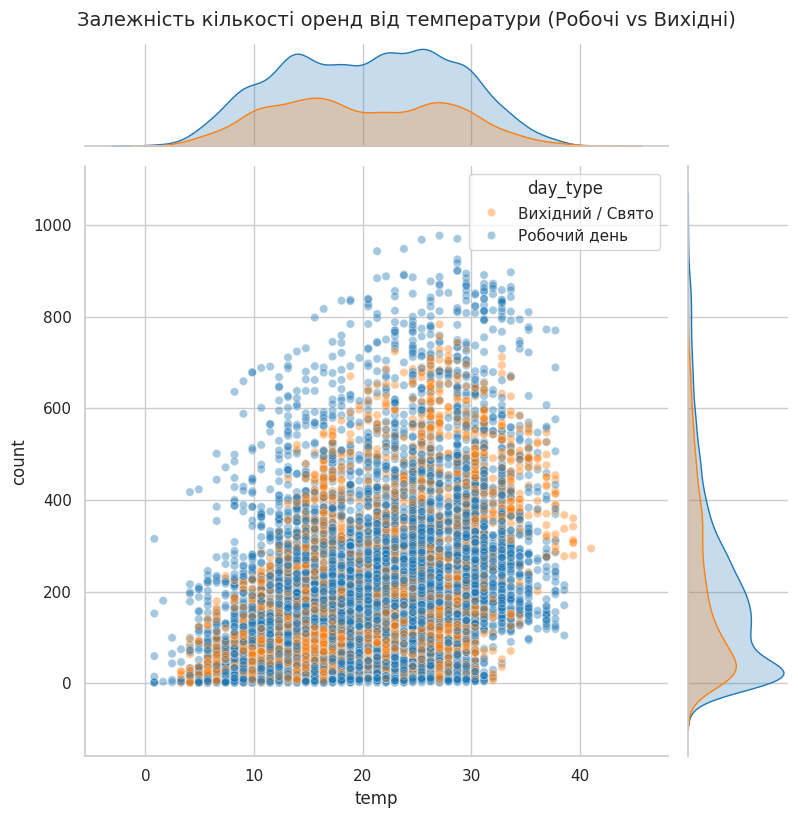

In [13]:
df['day_type'] = df['workingday'].map({1: 'Робочий день', 0: 'Вихідний / Свято'})

# 2. Побудова Joint Plot
g = sns.jointplot(
    data=df,
    x='temp',
    y='count',
    hue='day_type',
    palette=['#ff7f0e', '#1f77b4'], # Кольори для вихідних та робочих
    alpha=0.4,
    height=8
)

g.fig.suptitle('Залежність кількості оренд від температури (Робочі vs Вихідні)', y=1.02, fontsize=14)
plt.show()

Питання для інтерпретації:

Що показують графіки по краях? - За ним видно, що розподіл температур в обох типах днів практично однаковий  - погода не залежить від дня тижня.
Чи є різниця у поведінці користувачів у робочий і неробочий день? - немає. як в робочі так і у вихідні дні в холодну та спеконту погоду знижується кількість оренди.